In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "ec2"
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

REGION = "us-east-1"
YEAR = 2019
LINUX = "Linux/UNIX (Amazon VPC)"
COLS = ["record", "price", "timestamp", "instance_type", "os", "az"]
KEYS = ["instance_type", "az"]
print("ROOT:", ROOT, "| RAW ada?", RAW.exists())

ROOT: /home/frathol/KULIAH/RDA/dollar-auction-bandit | RAW ada? True


/home/frathol/KULIAH/RDA/dollar-auction-bandit/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def load_raw(region, year):
    files = sorted(RAW.glob(f"data.{region}.{year}-*.xz"))
    if not files:
        raise FileNotFoundError(f"Tidak ada berkas data.{region}.{year}-*.xz di {RAW}")
    parts = [pd.read_csv(f, sep="\t", header=None, names=COLS, compression="xz")
             for f in tqdm(files)]
    d = pd.concat(parts, ignore_index=True)
    n_mentah = len(d)
    d["timestamp"] = pd.to_datetime(d["timestamp"], utc=True)
    d = (d.drop(columns="record").drop_duplicates()
           .sort_values(["instance_type", "os", "az", "timestamp"])
           .reset_index(drop=True))
    return d, files, n_mentah

raw, files, n_mentah = load_raw(REGION, YEAR)
print(len(files), "berkas |", n_mentah, "baris mentah |", len(raw), "baris unik |",
      round(100 * (1 - len(raw) / n_mentah), 1), "% duplikat")

  0%|          | 0/347 [00:00<?, ?it/s]

100%|██████████| 347/347 [00:06<00:00, 53.40it/s]


347 berkas | 3977358 baris mentah | 2582550 baris unik | 35.1 % duplikat


In [3]:
f0 = files[len(files) // 2]
t0 = pd.read_csv(f0, sep="\t", header=None, names=COLS, nrows=8, compression="xz")
print("T0. Contoh baris mentah dari", f0.name)
display(t0)

skema = pd.DataFrame({
    "kolom": COLS,
    "tipe": t0.dtypes.astype(str).values,
    "arti": ["jenis catatan (selalu sama)", "harga spot (USD per jam)",
             "waktu harga mulai berlaku", "tipe instans", "sistem operasi/produk",
             "zona ketersediaan"],
    "contoh": t0.iloc[0].astype(str).values,
})
print("T1. Skema kolom")
display(skema)

ringkas = pd.Series({
    "region": REGION, "tahun (nama berkas)": YEAR,
    "berkas .xz dibaca": len(files),
    "baris mentah": n_mentah, "baris unik": len(raw),
    "persen duplikat": round(100 * (1 - len(raw) / n_mentah), 1),
    "tipe instans": raw["instance_type"].nunique(),
    "zona (az)": raw["az"].nunique(),
    "produk OS": raw["os"].nunique(),
    "seri (tipe x OS x zona)": raw.groupby(["instance_type", "os", "az"]).ngroups,
    "waktu awal (UTC)": str(raw["timestamp"].min()),
    "waktu akhir (UTC)": str(raw["timestamp"].max()),
}, name="nilai").to_frame()
print("T2. Ringkasan")
display(ringkas)

seri_unik = raw.drop_duplicates(["instance_type", "os", "az"])
t_os = (raw.groupby("os").agg(baris=("price", "size"), harga_median=("price", "median"))
          .join(seri_unik.groupby("os").size().rename("seri"))
          .sort_values("baris", ascending=False))
print("T3. Per sistem operasi")
display(t_os)

t_az = (raw.groupby("az").agg(baris=("price", "size"))
          .join(seri_unik.groupby("az").size().rename("seri"))
          .sort_values("baris", ascending=False))
print("T4. Per zona")
display(t_az)

raw["keluarga"] = raw["instance_type"].str.split(".").str[0]
t_fam = (raw.groupby("keluarga").agg(baris=("price", "size"),
                                     tipe=("instance_type", "nunique"),
                                     harga_median=("price", "median"))
           .sort_values("baris", ascending=False).head(15))
print("T5. Per keluarga instans (15 teratas)")
display(t_fam)

T0. Contoh baris mentah dari data.us-east-1.2019-07-11T00:06:01-07:00.xz


,record,price,timestamp,instance_type,os,az
0,SPOTINSTANCEPRICE,0.7936,2019-07-11T00:00:08-0700,c5d.9xlarge,Red Hat Enterprise Linux (Amazon VPC),us-east-1a
1,SPOTINSTANCEPRICE,0.7636,2019-07-11T00:00:08-0700,c5d.9xlarge,SUSE Linux (Amazon VPC),us-east-1a
2,SPOTINSTANCEPRICE,0.6636,2019-07-11T00:00:08-0700,c5d.9xlarge,Linux/UNIX (Amazon VPC),us-east-1a
3,SPOTINSTANCEPRICE,0.4632,2019-07-10T23:59:37-0700,m5a.4xlarge,Red Hat Enterprise Linux (Amazon VPC),us-east-1a
4,SPOTINSTANCEPRICE,0.4332,2019-07-10T23:59:37-0700,m5a.4xlarge,SUSE Linux (Amazon VPC),us-east-1a
5,SPOTINSTANCEPRICE,0.3332,2019-07-10T23:59:37-0700,m5a.4xlarge,Linux/UNIX (Amazon VPC),us-east-1a
6,SPOTINSTANCEPRICE,1.2518,2019-07-10T23:59:21-0700,p3.2xlarge,Red Hat Enterprise Linux (Amazon VPC),us-east-1d
7,SPOTINSTANCEPRICE,1.2218,2019-07-10T23:59:21-0700,p3.2xlarge,SUSE Linux (Amazon VPC),us-east-1d


T1. Skema kolom


,kolom,tipe,arti,contoh
0,record,str,jenis catatan (selalu sama),SPOTINSTANCEPRICE
1,price,float64,harga spot (USD per jam),0.7936
2,timestamp,str,waktu harga mulai berlaku,2019-07-11T00:00:08-0700
3,instance_type,str,tipe instans,c5d.9xlarge
4,os,str,sistem operasi/produk,Red Hat Enterprise Linux (Amazon VPC)
5,az,str,zona ketersediaan,us-east-1a


T2. Ringkasan


...

,baris,harga_median,seri
os,,,
Linux/UNIX (Amazon VPC),746986,0.2948,1251
SUSE Linux (Amazon VPC),746986,0.3948,1251
Red Hat Enterprise Linux (Amazon VPC),459806,0.4345,1243
Windows (Amazon VPC),400567,0.6900,1209
Windows,64382,0.3380,144
Linux/UNIX,64218,0.1234,144
SUSE Linux,64218,0.2234,144
Red Hat Enterprise Linux,35387,0.2534,144


T4. Per zona


,baris,seri
az,,
us-east-1d,545958,1143
us-east-1b,543144,1135
us-east-1a,524563,1131
us-east-1c,431109,945
us-east-1f,342208,811
us-east-1e,195568,365


T5. Per keluarga instans (15 teratas)


,baris,tipe,harga_median
keluarga,,,
r5,130359,9,0.5616
r4,128451,6,0.4668
m5,123461,9,0.4864
c5,116939,9,0.4217
m4,115238,6,0.4311
i3,113416,7,0.5132
r5d,110309,9,0.4730
m5d,104109,9,0.4549
r5a,95149,8,0.3340


In [4]:
piv = raw.pivot_table(index=["instance_type", "az", "timestamp"], columns="os",
                      values="price", aggfunc="last")
rows = []
if LINUX in piv.columns:
    for c in [x for x in piv.columns if x != LINUX]:
        d = (piv[c] - piv[LINUX]).dropna()
        g = d.groupby(level=[0, 1]).std().dropna()
        rows.append({"os": c, "pasangan_tipe_az": len(g),
                     "persen_offset_tetap(std<1e-6)": round(float((g < 1e-6).mean()), 3),
                     "std_maks": float(g.max())})
t_offset = pd.DataFrame(rows)
print("T6. Apakah selisih harga terhadap Linux/UNIX konstan?")
display(t_offset)

T6. Apakah selisih harga terhadap Linux/UNIX konstan?


,os,pasangan_tipe_az,persen_offset_tetap(std<1e-6),std_maks
0,Linux/UNIX,143,0.406,1.055701e-01
1,Red Hat Enterprise Linux,137,0.526,1.315285e-01
2,Red Hat Enterprise Linux (Amazon VPC),1243,1.000,1.310435e-15
3,SUSE Linux,143,0.406,1.055701e-01
4,SUSE Linux (Amazon VPC),1251,1.000,1.222875e-15
5,Windows,138,0.275,1.152789e-01
6,Windows (Amazon VPC),1135,0.275,1.334968e+00


In [5]:
lin = raw[raw["os"] == LINUX].copy()
lin = lin.sort_values(KEYS + ["timestamp"]).reset_index(drop=True)
lin["chg"] = lin.groupby(KEYS)["price"].diff().fillna(0) != 0
lin["dt_h"] = lin.groupby(KEYS)["timestamp"].diff().dt.total_seconds() / 3600

def tv(p):                               # total variation harga ternormalisasi median
    z = (p / p.median()).to_numpy()
    return float(np.abs(np.diff(z)).sum())

per = lin.groupby(KEYS).agg(
    n_catatan=("price", "size"),
    n_perubahan=("chg", "sum"),
    hari=("timestamp", lambda t: (t.max() - t.min()).days),
    median=("price", "median"),
    rentang_rel=("price", lambda p: (p.max() - p.min()) / p.median()),
)
per = per.join(lin[lin["chg"]].groupby(KEYS)["dt_h"].median().rename("selang_perubahan_jam"))
per["tv_per_hari"] = lin.groupby(KEYS)["price"].apply(tv) / per["hari"].clip(lower=1)
per["kelas"] = np.select(
    [per.hari < 300, per.n_perubahan == 0, per.n_perubahan < 100],
    ["pendek", "datar", "jarang"], default="aktif")

t_kelas = per["kelas"].value_counts().to_frame("jumlah_seri")
t_kelas["persen"] = (100 * t_kelas["jumlah_seri"] / t_kelas["jumlah_seri"].sum()).round(1)
t_kelas["median_perubahan"] = per.groupby("kelas")["n_perubahan"].median()
t_kelas["median_tv_per_hari"] = per.groupby("kelas")["tv_per_hari"].median().round(4)
print(len(per), "seri Linux/UNIX")
print("T7. Kelas seri")
display(t_kelas)
print("Seri aktif:")
display(per[per.kelas == "aktif"][["n_perubahan", "selang_perubahan_jam",
                                   "rentang_rel", "tv_per_hari"]].describe().round(3))

1251 seri Linux/UNIX
T7. Kelas seri


,jumlah_seri,persen,median_perubahan,median_tv_per_hari
kelas,,,,
aktif,553,44.2,796.0,0.0100
pendek,442,35.3,11.0,0.0031
jarang,141,11.3,38.0,0.0013
datar,115,9.2,0.0,0.0000


Seri aktif:


,n_perubahan,selang_perubahan_jam,rentang_rel,tv_per_hari
count,553.000,553.000,553.000,553.000
mean,792.669,6.264,0.786,0.012
std,457.841,0.533,1.083,0.012
min,106.000,5.718,0.019,0.000
25%,328.000,6.005,0.257,0.006
50%,796.000,6.133,0.382,0.010
75%,1252.000,6.277,0.821,0.016
max,1437.000,11.078,9.000,0.119


T8. Seri wakil


,,wakil,n_perubahan,selang_perubahan_jam,rentang_rel,tv_per_hari,kelas
instance_type,az,,,,,,
m5a.large,us-east-1b,aktif P25,538,6.697778,0.373656,0.005516,aktif
c4.2xlarge,us-east-1d,aktif P50,1084,6.408611,0.585987,0.010025,aktif
z1d.2xlarge,us-east-1b,aktif P75,293,6.138333,2.272251,0.015978,aktif
z1d.metal,us-east-1f,aktif P95,164,6.007222,2.333333,0.029166,aktif
x1e.8xlarge,us-east-1b,datar (hari terpanjang),0,NaN,0.000000,0.000000,datar


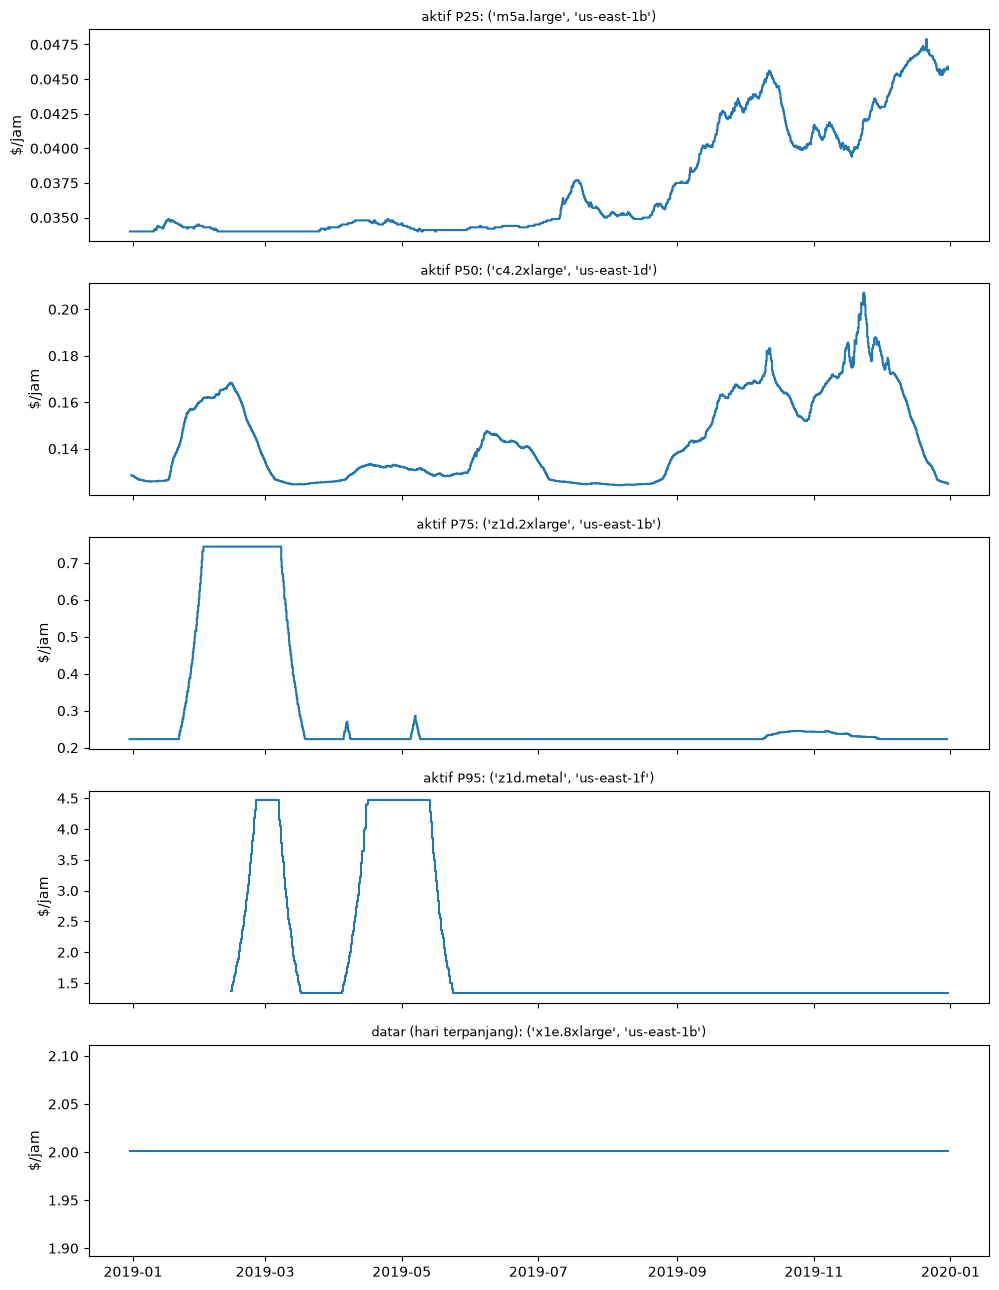

In [6]:
aktif = per[per.kelas == "aktif"].sort_values("tv_per_hari")
def at_q(q):
    return aktif.index[int(round(q * (len(aktif) - 1)))]

picks = {}
if len(aktif):
    picks = {f"aktif P{int(q * 100)}": at_q(q) for q in (0.25, 0.5, 0.75, 0.95)}
datar = per[per.kelas == "datar"]
if len(datar):
    picks["datar (hari terpanjang)"] = datar.sort_values("hari").index[-1]

def series(key):
    return lin[(lin["instance_type"] == key[0]) & (lin["az"] == key[1])]

t_picks = per.loc[list(picks.values()), ["n_perubahan", "selang_perubahan_jam",
                                         "rentang_rel", "tv_per_hari", "kelas"]].copy()
t_picks.insert(0, "wakil", list(picks.keys()))
print("T8. Seri wakil")
display(t_picks)

if picks:
    fig, axes = plt.subplots(len(picks), 1, figsize=(10, 2.6 * len(picks)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, (nama, key) in zip(axes, picks.items()):
        s = series(key)
        ax.step(s["timestamp"], s["price"], where="post")
        ax.set_title(f"{nama}: {key}", fontsize=9)
        ax.set_ylabel("$/jam")
    plt.tight_layout()
    plt.show()

In [7]:
def lag1(p):
    d = p.diff().dropna().to_numpy()
    d = d[d != 0]
    return np.corrcoef(d[:-1], d[1:])[0, 1] if len(d) >= 30 else np.nan

ac = lin.groupby(KEYS)["price"].apply(lag1).dropna()
res = pd.DataFrame({"lag1": ac, "n": per.loc[ac.index, "n_perubahan"]}).reset_index()
res["sig_pos"] = res["lag1"] > 2 / np.sqrt(res["n"])
res["sig_neg"] = res["lag1"] < -2 / np.sqrt(res["n"])
res["keluarga"] = res["instance_type"].str.split(".").str[0]
print("T9. Ringkasan lag-1:", len(res), "seri | signifikan positif:",
      round(res.sig_pos.mean(), 3), "| signifikan negatif:", round(res.sig_neg.mean(), 3))
display(res["lag1"].describe().round(3).to_frame("lag1"))
t_az_ac = res.groupby("az").agg(seri=("lag1", "size"), median_lag1=("lag1", "median"),
                                frac_pos=("sig_pos", "mean"), frac_neg=("sig_neg", "mean")).round(3)
print("T10. Lag-1 per zona")
display(t_az_ac)
t_fam_ac = (res.groupby("keluarga").agg(seri=("lag1", "size"), median_lag1=("lag1", "median"))
              .sort_values("seri", ascending=False).head(10).round(3))
print("T11. Lag-1 per keluarga (10 teratas)")
display(t_fam_ac)

T9. Ringkasan lag-1: 822 seri | signifikan positif: 0.918 | signifikan negatif: 0.015


,lag1
count,822.000
mean,0.476
std,0.275
min,-0.882
25%,0.299
50%,0.453
75%,0.716
max,0.932


T10. Lag-1 per zona


,seri,median_lag1,frac_pos,frac_neg
az,,,,
us-east-1a,169,0.433,0.893,0.012
us-east-1b,163,0.414,0.933,0.006
us-east-1c,153,0.551,0.935,0.026
us-east-1d,175,0.446,0.909,0.017
us-east-1e,46,0.372,0.913,0.022
us-east-1f,116,0.500,0.931,0.009


T11. Lag-1 per keluarga (10 teratas)


,seri,median_lag1
keluarga,,
r5,45,0.336
r5d,42,0.639
m5,41,0.363
r4,35,0.375
c5,35,0.292
m4,33,0.338
z1d,33,0.816
r5a,32,0.402
i3,32,0.431


In [8]:
tag = f"ec2_{REGION}_{YEAR}"
lin[KEYS + ["timestamp", "price"]].to_csv(OUT / f"{tag}_linux.csv.gz", index=False)   # besar: jangan commit
per.reset_index().to_csv(OUT / f"{tag}_linux_series_summary.csv", index=False)
t_picks.reset_index().to_csv(OUT / f"{tag}_picks_summary.csv", index=False)
res.to_csv(OUT / f"{tag}_lag1_summary.csv", index=False)
for nama, t in {"ringkasan": ringkas, "os": t_os, "az": t_az, "keluarga": t_fam,
                "offset_os": t_offset, "kelas": t_kelas}.items():
    t.to_csv(OUT / f"{tag}_{nama}_summary.csv")
print("Tersimpan di", OUT)

Tersimpan di /home/frathol/KULIAH/RDA/dollar-auction-bandit/data/processed
